# Geographic and taxonomic harmonization

One combined publication figure (`harmonization_metrics`): coordinate-validation outcomes and taxonomic match methods for images and for unique input taxa.

See [definitions and prerequisites](../README.md).


In [1]:
import sys
from pathlib import Path

ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "backend/app/configs/config.yaml").is_file()
)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import matplotlib.pyplot as plt
from analyses.helpers.publication import (
    align_panel_titles,
    category_plot,
    export_figure,
    geography_summaries,
    load_settings,
    publication_style,
    taxonomy_summaries,
)

settings = load_settings(ROOT)
publication_style()

In [3]:
geography = geography_summaries(settings)
taxonomy = taxonomy_summaries(settings)

## Combined geographic and taxonomic metrics


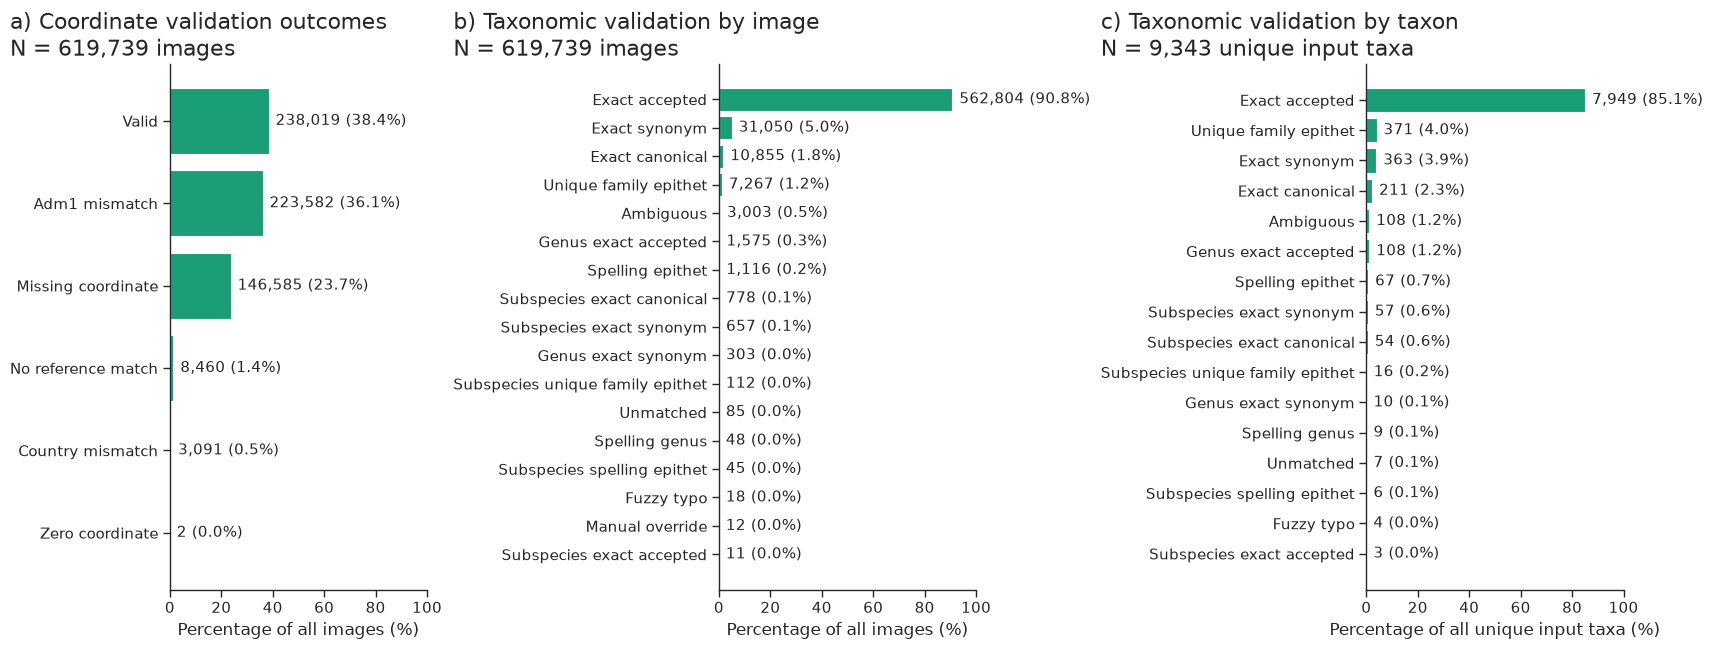

In [4]:
combined_metrics = {
    "geography_coordinate_validation": geography["coordinate_validation"],
    "taxonomy_images_method": taxonomy["images_method"],
    "taxonomy_taxa_method": taxonomy["taxa_method"],
}
fig, axes = plt.subplots(1, 3, figsize=(17, 6.5), layout="constrained")

for ax, frame, title in zip(
    axes,
    combined_metrics.values(),
    (
        "a) Coordinate validation outcomes",
        "b) Taxonomic validation by image",
        "c) Taxonomic validation by taxon",
    ),
    strict=True,
):
    category_plot(ax, frame, title, kind="bar")
    ax.tick_params(axis="x", labelsize=11)
    ax.tick_params(axis="y", labelsize=11)
    ax.xaxis.label.set_fontsize(12)

    for annotation in ax.texts:
        annotation.set_fontsize(11)

# Anchor each left-aligned title to its grid cell, so the headings line up
# whatever width each panel's tick labels take.
fig.canvas.draw()
fig.set_layout_engine(None)
align_panel_titles(axes)

for ax in axes:
    ax._left_title.set_fontsize(16)

export_figure(fig, settings, "harmonization_metrics", combined_metrics)
plt.show()
plt.close(fig)